# Education and Salary Analysis

## Exploratory Data Analysis

### Research Question

**Do occupations that typically require higher levels of education tend to have higher median annual salaries?**

### Hypothesis

**Occupations that typically require higher levels of education tend to have higher median annual salaries.**

### Data Source

This analysis uses the Career Explorer Occupational Level Data published by Iowa Workforce Development / Labor Market Information and accessed through Data.gov.

The dataset contains information about occupations, wages, typical education requirements, employment, geographic areas, skills, and other occupational characteristics.

In [1]:
# 1. Importing libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2. Loading the dataset

df = pd.read_csv(
    "career_explorer_occupational_level_data_1192_rows.csv"
)

df.head()

,geography,soc,occupational_title,job_title_soc,occupational_category,job_profile,url,estimated_employment,estimated_employment_year,projected_employment,...,ind_1,ind_2,ind_3,ind_4,ind_5,ind_6,ind_7,ind_8,ind_9,ind_10
0,State of Iowa,11-1011,Chief Executive,Chief Executive (11-1011),Management,Top executive responsible for overall strategi...,https://www.careeronestop.org/Videos/careerone...,4215,2022,3920,...,"Agriculture, Forestry, Fishing and Hunting",Construction,"Self Employed and Unpaid Family Workers, All Jobs",Manufacturing,Finance and Insurance,Other Services (except Government),Retail Trade,Transportation and Warehousing,Health Care and Social Assistance,Real Estate and Rental and Leasing
1,State of Iowa,11-9121,Natural Sciences Manager,Natural Sciences Manager (11-9121),Management,Coordinates research and development activitie...,https://www.careeronestop.org/Videos/careerone...,620,2022,675,...,Government,"Professional, Scientific, and Technical Services",Educational Services,Manufacturing,Other Services (except Government),Wholesale Trade,NaN,NaN,NaN,NaN
2,State of Iowa,15-1243,Database Architect,Database Architect (15-1243),Computer & Mathematical,Design and build databases to meet the storage...,https://www.careeronestop.org/Videos/careerone...,275,2022,300,...,Finance and Insurance,Management of Companies and Enterprises,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,State of Iowa,17-2072,"Electronics Engineer, Except Computer","Electronics Engineer, Except Computer (17-2072)",Architecture & Engineering,Designs and develops electronic components and...,https://www.careeronestop.org/Videos/careerone...,380,2022,435,...,Information,Manufacturing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,State of Iowa,19-1011,Animal Scientist,Animal Scientist (19-1011),"Life, Physical, & Social Science","Conducts research on genetics, nutrition, repr...",https://www.careeronestop.org/Videos/careerone...,305,2022,315,...,"Agriculture, Forestry, Fishing and Hunting",Wholesale Trade,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Understanding the Dataset

Before analyzing the relationship between education requirements and salaries, I first examined the structure and size of the dataset.

Each row represents an occupation within a specific geographic area, so the same occupation may appear more than once across different locations.

In [3]:
# 3. Checking the number of rows and columns

pd.DataFrame({
    "Rows": [df.shape[0]],
    "Columns": [df.shape[1]]
})

,Rows,Columns
0,40048,91


 #### **Finding:**  

*The dataset contains 40,048 observations and 91 variables. Because the dataset contains many variables beyond those needed for my research question, I will identify the variables most relevant to education requirements and occupational salaries before continuing the analysis.*

In [4]:
# 4. Reviewing all column names

pd.DataFrame({
    "Column": df.columns
})

,Column
0,geography
1,soc
2,occupational_title
3,job_title_soc
4,occupational_category
...,...
86,ind_6
87,ind_7
88,ind_8
89,ind_9


### Data Types

I reviewed the data types to understand which variables are numeric, categorical, or text-based before beginning the analysis.

In [5]:
# 5. Reviewing data types

pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

,Column,Data Type
0,geography,str
1,soc,str
2,occupational_title,str
3,job_title_soc,str
4,occupational_category,str
...,...,...
86,ind_6,str
87,ind_7,str
88,ind_8,str
89,ind_9,str


### Missing Values

I checked for missing values to identify variables that may require cleaning before the analysis.

In [6]:
# 6. Checking missing values

missing_values = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isna().sum().values,
    "Percent Missing": (df.isna().mean().values * 100).round(2)
})

missing_values[missing_values["Missing Values"] > 0]

,Column,Missing Values,Percent Missing
12,new_openings,16251,40.58
15,entry_level_hourly_wage,1876,4.68
16,average_hourly_wage,1876,4.68
17,median_hourly_wage,2012,5.02
18,experienced_level_hourly_wage,1913,4.78
...,...,...,...
86,ind_6,28876,72.10
87,ind_7,30551,76.29
88,ind_8,32173,80.34
89,ind_9,33397,83.39


#### **Finding:**  

*The dataset contains missing values in 62 of the 91 columns. Some variables have a relatively small amount of missing data, while others have much larger percentages. For example, `new_openings` is missing about 40.58% of its values, and several industry-related variables (`ind_6` through `ind_10`) have more than 70% missing data.*

*Because my research question focuses mainly on education requirements and annual salary, I will pay closer attention to missing values in those variables rather than removing rows based on unrelated columns.*

### Duplicate Rows

I also checked whether the dataset contains any completely duplicated rows.

In [7]:
# 7. Checking duplicate rows

pd.DataFrame({
    "Duplicate Rows": [df.duplicated().sum()]
})

,Duplicate Rows
0,0


#### **Finding:**  

*There are no completely duplicated rows in the dataset. Therefore, no rows need to be removed because of exact duplication at this stage.*

## 2. Exploring the Main Variables

My research question focuses on the relationship between an occupation's typical education requirement and its median annual salary. Before comparing these variables, I examined their completeness and distributions.

In [8]:
# 8. Checking the main variables

main_variables = pd.DataFrame({
    "Variable": [
        "typical_education_requirement",
        "median_annual_salary"
    ],
    "Missing Values": [
        df["typical_education_requirement"].isna().sum(),
        df["median_annual_salary"].isna().sum()
    ],
    "Percent Missing": [
        df["typical_education_requirement"].isna().mean() * 100,
        df["median_annual_salary"].isna().mean() * 100
    ]
})

main_variables["Percent Missing"] = main_variables["Percent Missing"].round(2)

main_variables

,Variable,Missing Values,Percent Missing
0,typical_education_requirement,0,0.00
1,median_annual_salary,1970,4.92


#### **Finding:**  

*`typical_education_requirement` has no missing values, while `median_annual_salary` has 1,970 missing values, which is about 4.92% of the dataset. Since salary is essential to my research question, rows with missing median annual salary will need to be excluded from salary-based comparisons.*

In [ ]:
# 9. Defining education levels from lowest to highest

education_order = [
    "No Formal Educational Credential",
    "High School Diploma or Equivalent",
    "Some College, No Degree",
    "Postsecondary Non-Degree Award",
    "Associate Degree",
    "Bachelor's Degree",
    "Master's Degree",
    "Doctoral or Professional Degree"
]

### Education Requirement Categories

I examined the education categories to understand how occupations are distributed across different levels of typical educational requirements.

In [ ]:
# 10. Counting occupations by education requirement in logical order

education_counts = (
    df["typical_education_requirement"]
    .value_counts()
    .reindex(education_order)
    .rename_axis("Education Requirement")
    .reset_index(name="Count")
)

education_counts

,Education Requirement,Count
0,No Formal Educational Credential,5862
1,High School Diploma or Equivalent,17036
2,"Some College, No Degree",572
3,Postsecondary Non-Degree Award,2644
4,Associate Degree,2242
5,Bachelor's Degree,8845
6,Master's Degree,1336
7,Doctoral or Professional Degree,1511


#### **Finding:**  

*The education categories are now arranged from the lowest to the highest typical education requirement. High School Diploma or Equivalent is the most common category with **17,036** observations, followed by Bachelor's Degree with **8,845** observations. Some categories, such as Some College, No Degree and Master's Degree, have much smaller sample sizes, so the groups are not evenly represented.*

### Median Annual Salary

I examined the distribution of median annual salary to understand its center, spread, and possible extreme values.

In [ ]:
# 11. Summary statistics for median annual salary

df["median_annual_salary"].describe().to_frame(
    name="Median Annual Salary"
)

,Median Annual Salary
count,38078.000000
mean,54041.002500
std,22732.537237
min,20509.000000
25%,38345.000000
50%,48164.000000
75%,62124.250000
max,229954.000000


#### **Finding:**  

*There are 38,078 observations with available median annual salary data. The median annual salary is **`$48,164`**, while the mean is about **`$54,041`**. Since the mean is higher than the median, the salary distribution may be right-skewed. Salaries range from about **`$20,509`** to **`$229,954`**, suggesting that some occupations have much higher salaries than most others.*

### Salary Distribution

I used a histogram and boxplot to examine the shape of the salary distribution and identify possible outliers.

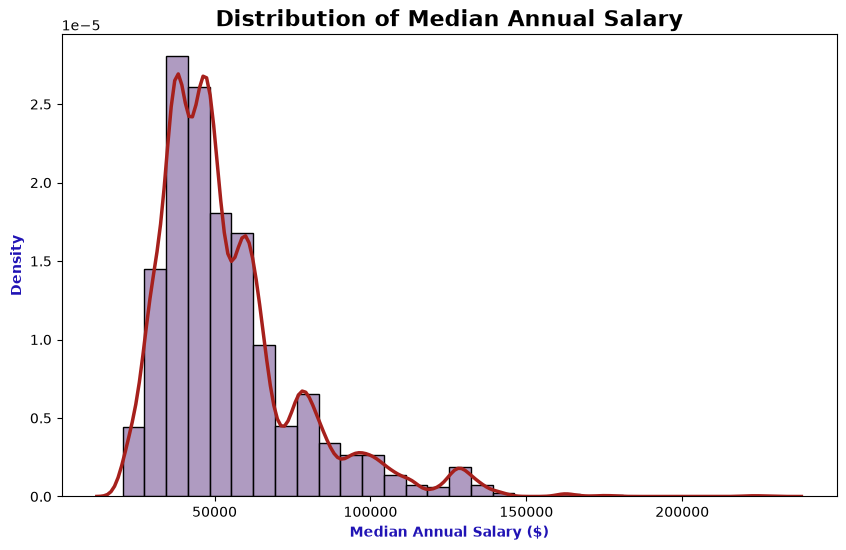

In [ ]:
# 12. Histogram of median annual salary with custom colors

plt.figure(figsize=(10, 6))

# Histogram bars
sns.histplot(
    data=df,
    x="median_annual_salary",
    bins=30,
    stat="density",
    color="#947AAD",
    edgecolor="black"
)

# KDE line
sns.kdeplot(
    data=df,
    x="median_annual_salary",
    color="#A6201C",
    linewidth=2.5
)

# Title and axis labels with different colors
plt.title("Distribution of Median Annual Salary", 
    color="black",
    fontweight="bold",
    fontsize=16
)

plt.xlabel("Median Annual Salary ($)", 
    color="#2114B5", 
    fontweight="bold" 
)

plt.ylabel("Density", 
    color="#2114B5",
    fontweight="bold"
)

# Tick label colors
plt.xticks(color="black")
plt.yticks(color="black")

plt.show()

#### **Finding:**  

*The histogram shows that **median annual salary is right-skewed**, with most observations concentrated toward the lower end of the salary distribution and a long tail extending toward higher salaries. This pattern is consistent with the summary statistics, where the mean salary (**`$54,041`**) is higher than the median salary (**`$48,164`**).*

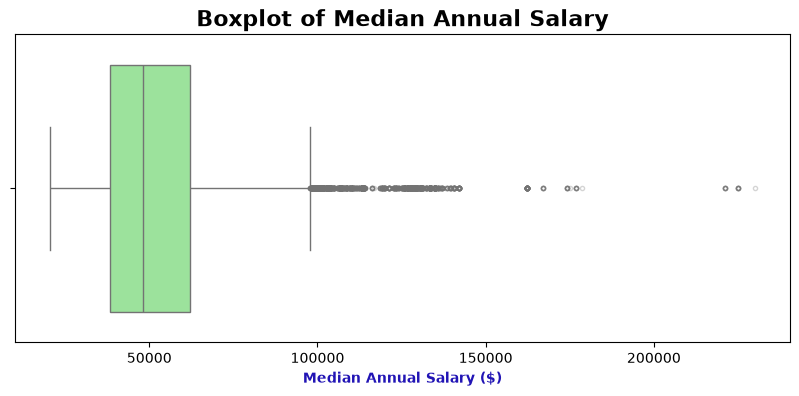

In [ ]:
# 13. Boxplot of median annual salary with smaller outliers

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="median_annual_salary",
    color="lightgreen",
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.3}
)

plt.title("Boxplot of Median Annual Salary",
    color="black",
    fontweight="bold",
    fontsize=16
)

plt.xlabel("Median Annual Salary ($)",
    color="#2114B5",
    fontweight="bold"
)

plt.show()

#### **Finding:**  

*The boxplot shows that most median annual salaries are concentrated within a relatively narrow range, while many observations fall above the upper whisker. These higher values are potential outliers and confirm that the salary distribution contains several unusually high-paying occupations.*

### **Identifying Salary Outliers**

The boxplot suggests that there are several unusually high salary values. I used the Interquartile Range (IQR) method to calculate the lower and upper bounds for potential outliers.


$$IQR = Q_3 - Q_1$$


$$\text{Lower Bound} = Q_1 - 1.5(IQR)$$


$$\text{Upper Bound} = Q_3 + 1.5(IQR)$$


In [ ]:
# 14. Calculating IQR and outlier bounds for median annual salary

Q1 = df["median_annual_salary"].quantile(0.25)
Q3 = df["median_annual_salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_summary = pd.DataFrame({
    "Statistic": ["Q1", "Q3", "IQR", "Lower Bound", "Upper Bound"],
    "Value": [Q1, Q3, IQR, lower_bound, upper_bound]
})

outlier_summary

,Statistic,Value
0,Q1,38345.000
1,Q3,62124.250
2,IQR,23779.250
3,Lower Bound,2676.125
4,Upper Bound,97793.125


In [ ]:
# 15. Counting potential salary outliers

salary_outliers = df[
    (df["median_annual_salary"] < lower_bound) |
    (df["median_annual_salary"] > upper_bound)
]

pd.DataFrame({
    "Number of Potential Outliers": [len(salary_outliers)]
})

,Number of Potential Outliers
0,2263


In [ ]:
# 16. Viewing the highest salary outliers

salary_outliers[
    ["occupational_title", "median_annual_salary"]
].sort_values(
    "median_annual_salary",
    ascending=False
).head(10)

,occupational_title,median_annual_salary
15101,Nurse Anesthetist,229954.0
11481,Musician & Singer,224972.8
9616,Musician & Singer,224972.8
12561,Musician & Singer,224972.8
9354,Musician & Singer,224972.8
13283,Musician & Singer,224972.8
7979,Musician & Singer,224972.8
2295,Musician & Singer,224972.8
4654,Musician & Singer,224972.8
16523,Nurse Anesthetist,221205.0


#### **Finding:**  

*The IQR method identified 2,263 potential salary outliers. The upper outlier threshold is approximately **`$97,793`**, and the highest salaries in the dataset exceed **`$220,000`**.*

*The highest values are associated with occupations such as Nurse Anesthetists and Musicians & Singers. Because these values correspond to real occupations and may reflect differences across geographic areas, I will not automatically remove them. Instead, I will keep them unless later analysis suggests that they are data errors or inappropriate for the comparison.*

## 3. Education Level vs. Salary

To explore my hypothesis, I compared median annual salaries across the different typical education requirement categories.

In [ ]:
# 17. Median annual salary by education requirement

salary_by_education = (
    df.groupby("typical_education_requirement")["median_annual_salary"]
    .median()
    .reindex(education_order)
    .reset_index()
)

salary_by_education.columns = [
    "Education Requirement",
    "Median Annual Salary"
]

salary_by_education

,Education Requirement,Median Annual Salary
0,No Formal Educational Credential,33544.0
1,High School Diploma or Equivalent,45179.0
2,"Some College, No Degree",39801.0
3,Postsecondary Non-Degree Award,47540.0
4,Associate Degree,58573.0
5,Bachelor's Degree,65315.0
6,Master's Degree,76321.0
7,Doctoral or Professional Degree,79572.0


#### **Finding:**  

*When the education categories are arranged from lowest to highest, median annual salary generally increases as education requirements increase. Occupations requiring no formal educational credential have a median salary of about **`$33,544`**, while occupations requiring a doctoral or professional degree have the highest median salary at about **`$79,572.3`**.*

*There is a small exception between High School Diploma or Equivalent and Some College, No Degree, where the median salary decreases slightly. Overall, however, the pattern still supports a positive relationship between education requirement and salary.*

### Median Salary by Education Requirement

The median salary for each education category provides a simple way to compare typical earnings across different education levels.

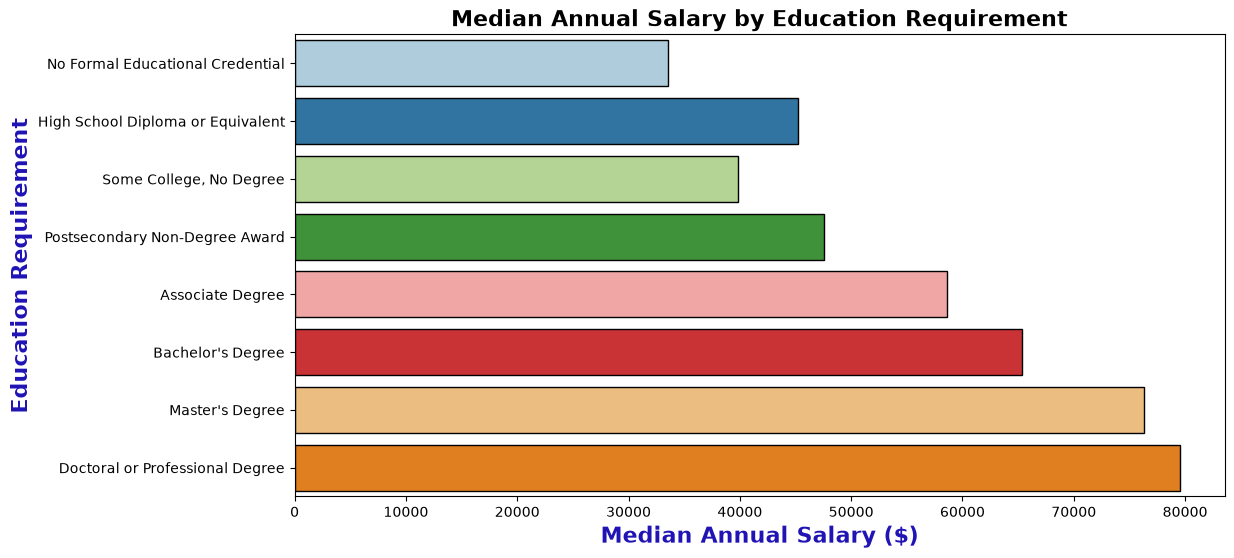

In [ ]:
# 18. Bar chart of median annual salary by education requirement

plt.figure(figsize=(12, 6))

sns.barplot(
    data=salary_by_education,
    y="Education Requirement",
    x="Median Annual Salary",
    hue="Education Requirement",
    palette="Paired",
    legend=False,
    edgecolor="black"
)

plt.title(
    "Median Annual Salary by Education Requirement",
    fontweight="bold",
    fontsize=16
)

plt.xlabel(
    "Median Annual Salary ($)",
    color="#2114B5",
    fontweight="bold",
    fontsize=16
)

plt.ylabel(
    "Education Requirement",
    color="#2114B5",
    fontweight="bold",
    fontsize=16
)

plt.show()

#### **Finding:**  

*The bar chart shows an overall upward pattern in median annual salary as education requirements increase. Occupations requiring lower levels of formal education generally have lower median salaries, while occupations requiring Associate, Bachelor's, Master's, or Doctoral or Professional Degrees tend to have higher median salaries.*

*There is a small exception between High School Diploma or Equivalent and Some College, No Degree, where the median salary decreases slightly. The highest median salary is for occupations requiring a Doctoral or Professional Degree at about **`$79,572`**, compared with about **`$33,544`** for occupations requiring No Formal Educational Credential.*

*Overall, the visual pattern provides initial support for my hypothesis that higher education requirements are associated with higher occupational salaries.*

### Salary Distribution by Education Requirement

The median salary comparison shows an overall increase across education levels. I also used a boxplot to examine the variation and overlap in salaries within each education requirement category.

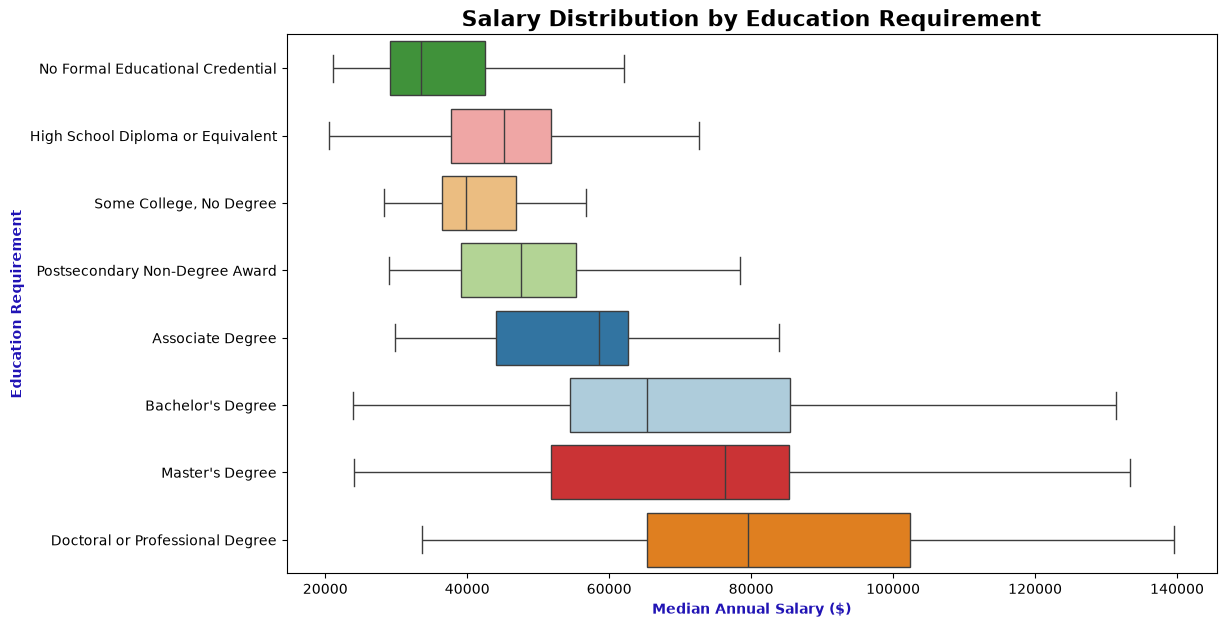

In [ ]:
# 19. Boxplot of median annual salary by education requirement

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    y="typical_education_requirement",
    x="median_annual_salary",
    order=education_order,
    hue="typical_education_requirement",
    palette="Paired",
    legend=False,
    showfliers=False
)

plt.title(
    "Salary Distribution by Education Requirement",
    fontweight="bold",
    fontsize=16
)

plt.xlabel(
    "Median Annual Salary ($)",
    color="#2114B5",
    fontweight="bold"
)

plt.ylabel(
    "Education Requirement",
    color="#2114B5",
    fontweight="bold"
)

plt.show()

#### **Finding:**  

*With the education categories arranged from lowest to highest, the boxplot shows a clearer overall upward shift in salary distributions as education requirements increase. Occupations requiring Bachelor's, Master's, and Doctoral or Professional Degrees generally have higher salary distributions than occupations requiring lower levels of education.*

*There is still overlap between the groups, which shows that education requirement does not completely determine salary. However, the overall pattern remains consistent with my hypothesis that occupations requiring higher levels of education tend to have higher salaries.*

## 4. EDA Checkpoint Summary

*The exploratory analysis shows a clear overall relationship between education requirements and median annual salary. The dataset contains 40,048 observations and 91 variables, with 1,970 missing values in `median_annual_salary`.*

*Salary is right-skewed and includes several high-value outliers, but these appear to represent real occupations rather than obvious data errors. When the education categories are ordered from the lowest to the highest requirement, median annual salary generally increases as education requirements increase. There is a small exception between High School Diploma or Equivalent and Some College, No Degree, but the overall upward pattern remains clear.*

*The boxplot also shows that salary distributions overlap across education groups, suggesting that education requirement alone does not fully explain salary differences. Further statistical testing will be needed to determine whether the observed relationship provides sufficient evidence to support the hypothesis.*